In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Matplotlib is building the font cache; this may take a moment.


Libraries imported successfully!


In [2]:
import os

print("Current folder:", os.getcwd())
print("Image exists:", os.path.exists("parrot.jpeg.jpg"))

Current folder: C:\Users\User
Image exists: True


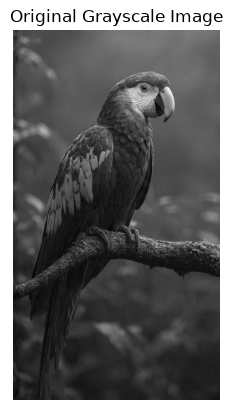

In [3]:
gray = cv2.imread("parrot.jpeg.jpg", cv2.IMREAD_GRAYSCALE)

plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")
plt.show()

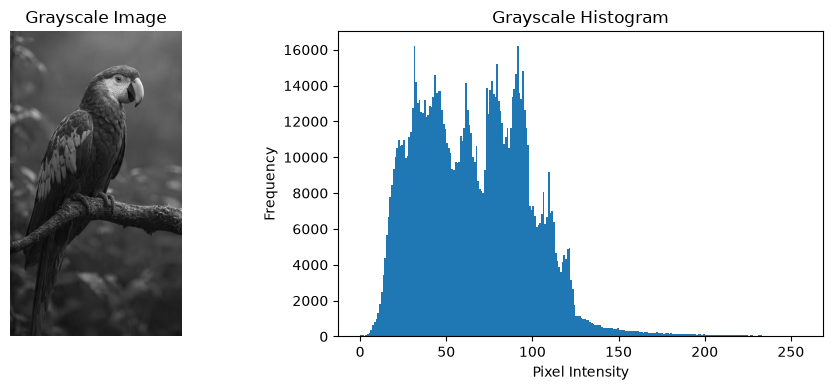

In [4]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.hist(gray.ravel(), bins=256, range=(0, 256))
plt.title("Grayscale Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

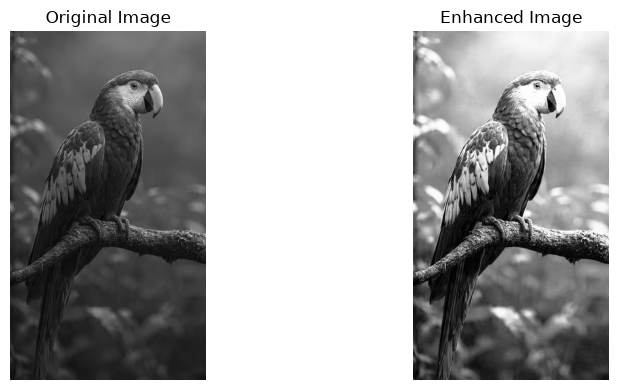

In [5]:
equalized = cv2.equalizeHist(gray)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(equalized, cmap="gray")
plt.title("Enhanced Image")
plt.axis("off")

plt.tight_layout()
plt.show()

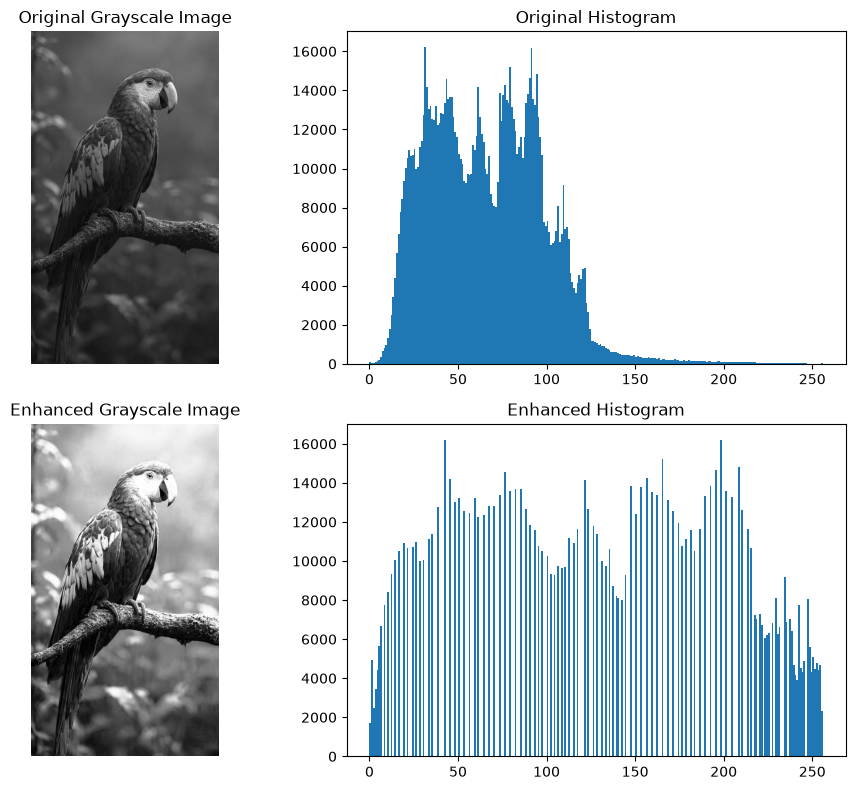

In [6]:
plt.figure(figsize=(10, 8))

plt.subplot(2, 2, 1)
plt.imshow(gray, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.hist(gray.ravel(), bins=256, range=(0, 256))
plt.title("Original Histogram")

plt.subplot(2, 2, 3)
plt.imshow(equalized, cmap="gray")
plt.title("Enhanced Grayscale Image")
plt.axis("off")

plt.subplot(2, 2, 4)
plt.hist(equalized.ravel(), bins=256, range=(0, 256))
plt.title("Enhanced Histogram")

plt.tight_layout()
plt.show()

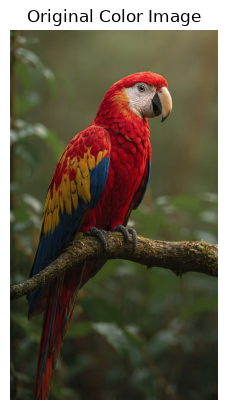

In [7]:
color = cv2.imread("parrot.jpeg.jpg")

if color is None:
    raise FileNotFoundError("Check the image filename!")

plt.imshow(cv2.cvtColor(color, cv2.COLOR_BGR2RGB))
plt.title("Original Color Image")
plt.axis("off")
plt.show()

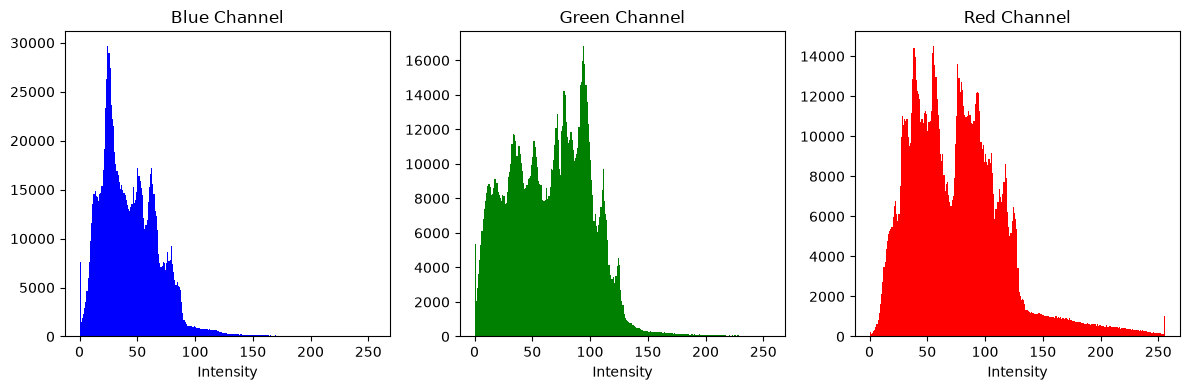

In [8]:
b, g, r = cv2.split(color)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.hist(b.ravel(), bins=256, range=(0, 256), color="blue")
plt.title("Blue Channel")
plt.xlabel("Intensity")

plt.subplot(1, 3, 2)
plt.hist(g.ravel(), bins=256, range=(0, 256), color="green")
plt.title("Green Channel")
plt.xlabel("Intensity")

plt.subplot(1, 3, 3)
plt.hist(r.ravel(), bins=256, range=(0, 256), color="red")
plt.title("Red Channel")
plt.xlabel("Intensity")

plt.tight_layout()
plt.show()

In [9]:
hsv = cv2.cvtColor(color, cv2.COLOR_BGR2HSV)

h, s, v = cv2.split(hsv)

print("Converted to HSV successfully!")

Converted to HSV successfully!


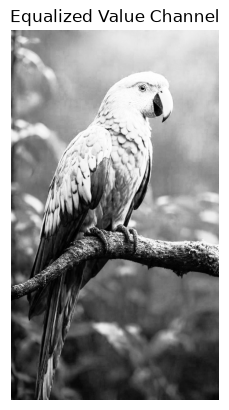

In [11]:
v_equalized = cv2.equalizeHist(v)

plt.imshow(v_equalized, cmap="gray")
plt.title("Equalized Value Channel")
plt.axis("off")
plt.show()

In [12]:
hsv_equalized = cv2.merge((h, s, v_equalized))

enhanced_color = cv2.cvtColor(
    hsv_equalized, cv2.COLOR_HSV2BGR
)

print("Color enhancement completed!")

Color enhancement completed!


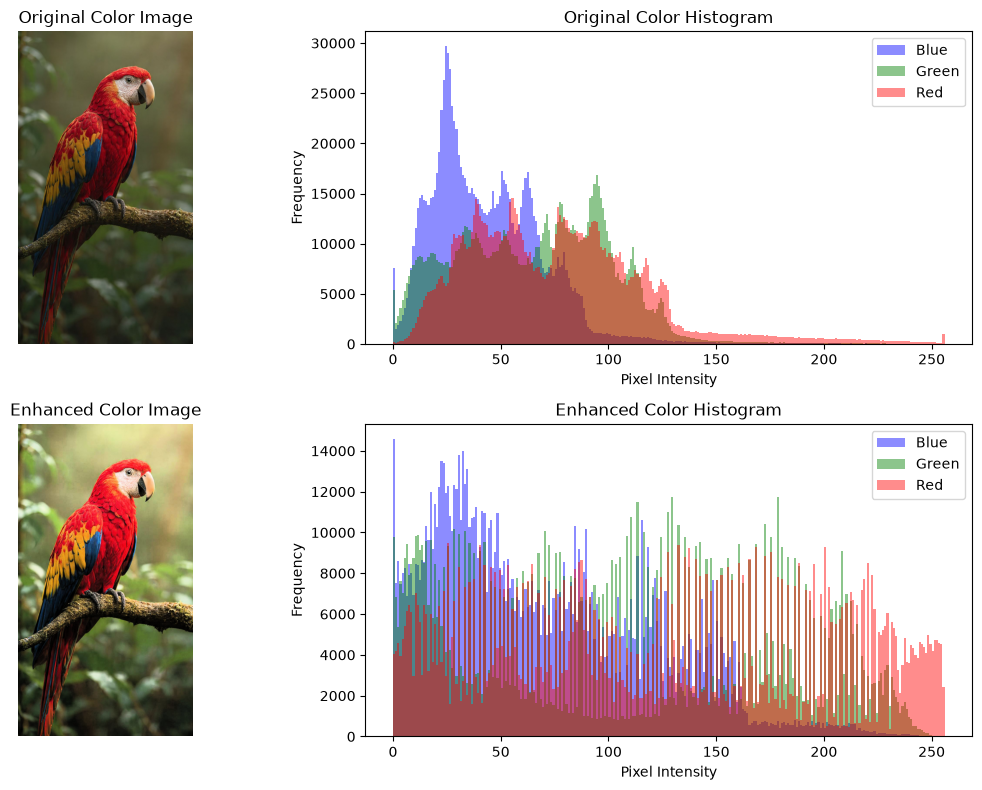

In [13]:
plt.figure(figsize=(12, 8))

# Original color image
plt.subplot(2, 2, 1)
plt.imshow(cv2.cvtColor(color, cv2.COLOR_BGR2RGB))
plt.title("Original Color Image")
plt.axis("off")

# Original histogram
plt.subplot(2, 2, 2)

for channel, col, name in [
    (b, "blue", "Blue"),
    (g, "green", "Green"),
    (r, "red", "Red")
]:
    plt.hist(channel.ravel(), bins=256,
             range=(0, 256), color=col,
             alpha=0.45, label=name)

plt.title("Original Color Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.legend()

# Enhanced color image
plt.subplot(2, 2, 3)
plt.imshow(cv2.cvtColor(enhanced_color, cv2.COLOR_BGR2RGB))
plt.title("Enhanced Color Image")
plt.axis("off")

# Enhanced histogram
plt.subplot(2, 2, 4)

eb, eg, er = cv2.split(enhanced_color)

for channel, col, name in [
    (eb, "blue", "Blue"),
    (eg, "green", "Green"),
    (er, "red", "Red")
]:
    plt.hist(channel.ravel(), bins=256,
             range=(0, 256), color=col,
             alpha=0.45, label=name)

plt.title("Enhanced Color Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.legend()

plt.tight_layout()
plt.show()